# 04. Random forests: bagging, out-of-bag error, and two kinds of importance

A random forest grows hundreds of deep trees, each on a bootstrap sample of water bodies and choosing
each split from a random subset of features (`max_features`), then averages their votes.

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))

## Out-of-bag error looks reassuring and is wrong here

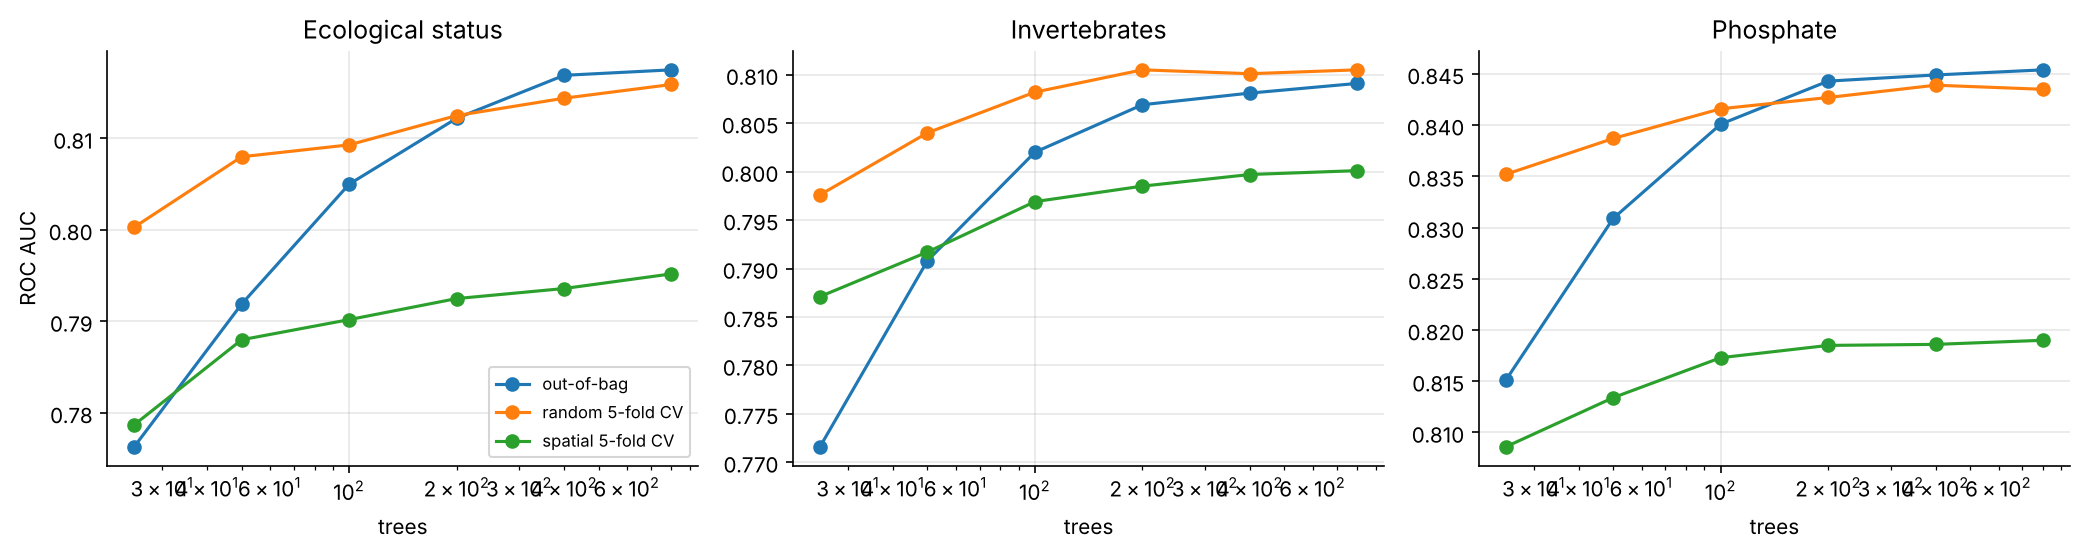

,target,oob_auc,random_cv_auc,spatial_cv_auc
4,eco_good,0.817,0.814,0.794
13,inv_good,0.808,0.810,0.800
22,phos_good,0.845,0.844,0.819


In [2]:
display(Image(FIG / "forest_oob_vs_spatial.png"))
f = pd.read_csv(T / "forest_study.csv")
f[f.max_features.isna() & (f.n_trees == 400)][["target", "oob_auc", "random_cv_auc", "spatial_cv_auc"]].round(3)

Each tree's out-of-bag rows are a free test set, but they are **neighbours** of the training rows:
a water body left out of one bootstrap sample usually has its upstream and downstream neighbours in it.
OOB AUC therefore tracks random-fold CV, and both overstate how well the forest predicts a catchment
it has never seen. Every reported score in this project uses spatial folds (whole management catchments held out).

In [3]:
f[f.max_features.notna()][["target", "max_features", "spatial_cv_auc"]].round(3)

,target,max_features,spatial_cv_auc
6,eco_good,sqrt,0.794
7,eco_good,0.5,0.783
8,eco_good,1.0,0.776
15,inv_good,sqrt,0.800
16,inv_good,0.5,0.797
17,inv_good,1.0,0.794
24,phos_good,sqrt,0.818
25,phos_good,0.5,0.817
26,phos_good,1.0,0.814


`max_features="sqrt"` (about 6 of 32 features per split) beats using every feature: decorrelating
the trees matters more than making each tree strong.

## Impurity importance vs permutation importance

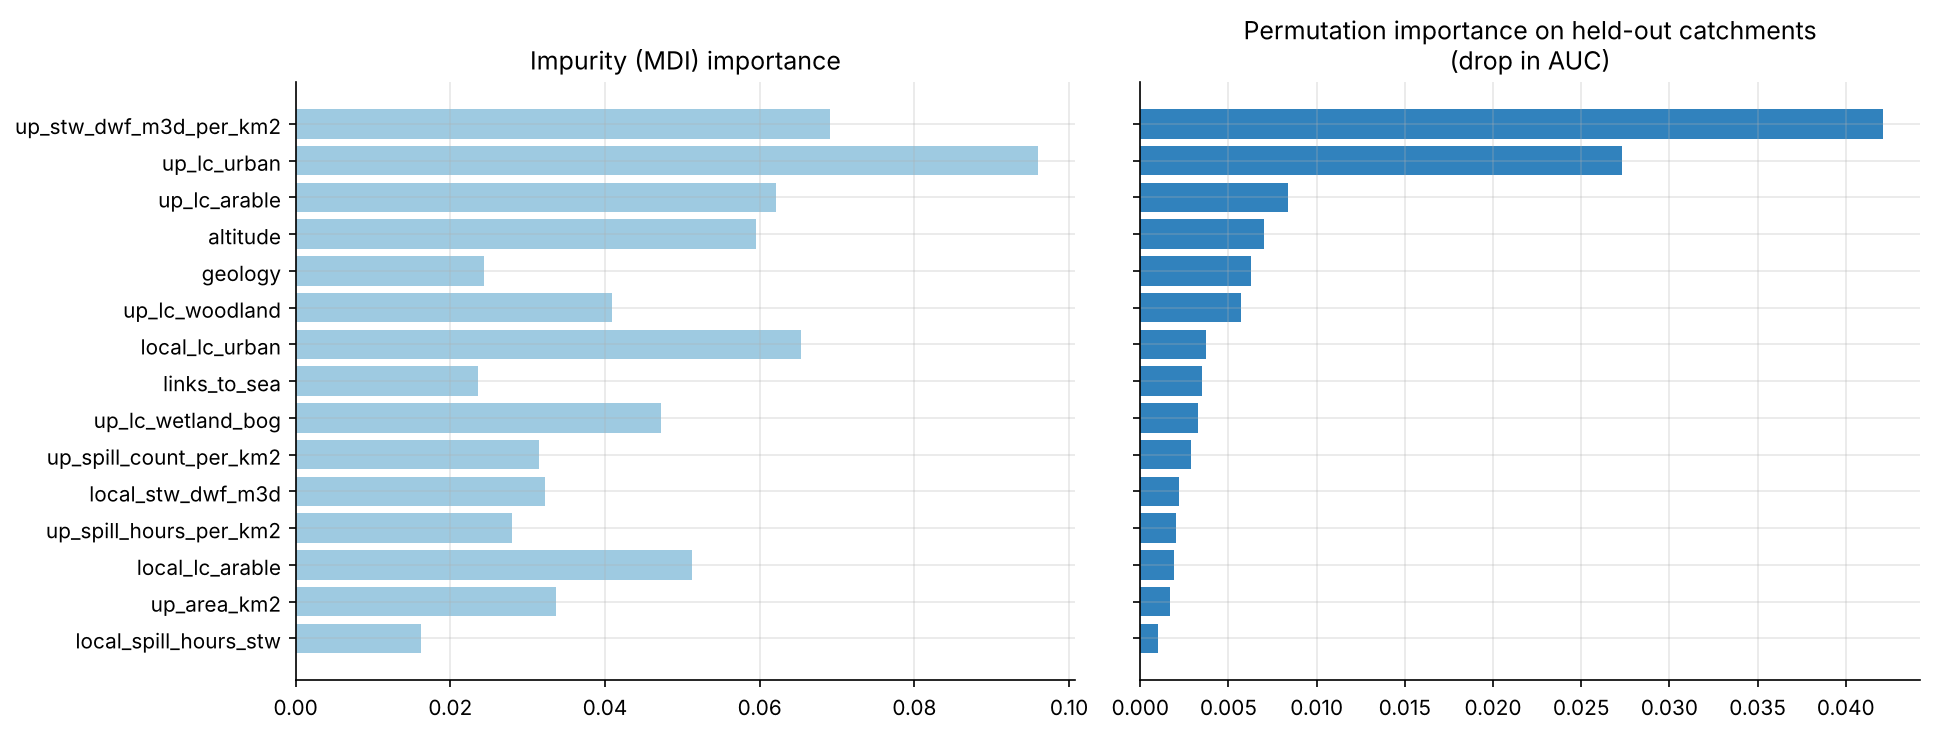

,target,feature,impurity,permutation_auc_drop,impurity_rank,permutation_rank
89,phos_good,up_stw_dwf_m3d_per_km2,0.0691,0.0421,2.0,1.0
96,phos_good,up_lc_urban,0.0960,0.0273,1.0,2.0
94,phos_good,up_lc_arable,0.0621,0.0084,4.0,3.0
69,phos_good,altitude,0.0595,0.0070,5.0,4.0
71,phos_good,geology,0.0243,0.0063,19.0,5.0
79,phos_good,up_lc_woodland,0.0409,0.0057,8.0,6.0
99,phos_good,local_lc_urban,0.0653,0.0037,3.0,7.0
74,phos_good,links_to_sea,0.0236,0.0035,20.0,8.0
78,phos_good,up_lc_wetland_bog,0.0473,0.0033,7.0,9.0
82,phos_good,up_spill_count_per_km2,0.0315,0.0029,16.0,10.0


In [4]:
display(Image(FIG / "forest_importance_phos.png"))
imp = pd.read_csv(T / "forest_importance.csv")
w = imp[imp.target == "phos_good"].assign(
    impurity_rank=lambda d: d.impurity.rank(ascending=False),
    permutation_rank=lambda d: d.permutation_auc_drop.rank(ascending=False))
w.sort_values("permutation_rank").head(12).round(4)

Impurity (MDI) importance rewards continuous features with many possible split points and is computed on
the training data. Permutation importance asks how much the held-out AUC falls when one feature's values
are shuffled. With correlated features it under-states each one (the others stand in), which is why
the project groups features by pressure in the SHAP analysis (notebook 06).